# 05 — Feature Engineering

**Module 02 input.** One row per (grid cell, observation month): trailing
activity features and a 30-day forecasting target.

This notebook verifies the three properties that make the dataset trustworthy:

1. **Temporal contract** — features only use the past, targets only the future
2. **Class balance** — how rare the target actually is
3. **Spot-check correctness** — stored features recomputed independently from
   the raw catalog and compared row by row

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from seismo.config import load_config
from seismo.features.engineering import feature_columns
from seismo.geospatial.analysis import NAMED_REGIONS, grid_from_config

In [2]:
# Locate the project root so data paths resolve whether the notebook runs
# interactively from the repo root or is executed by nbconvert from notebooks/.
# (Imports above are unaffected — `seismo` is installed as a package.)
for _candidate in [Path.cwd(), *Path.cwd().parents]:
    if (_candidate / "config" / "config.yaml").is_file():
        os.chdir(_candidate)
        break

sns.set_theme(style="whitegrid", font_scale=1.1)

NAVY = "#14263D"
ACCENT = "#2583A6"
LIGHT = "#E9EEF3"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.edgecolor": NAVY,
    "axes.labelcolor": NAVY,
    "text.color": NAVY,
    "xtick.color": NAVY,
    "ytick.color": NAVY,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "figure.dpi": 150,
})

cfg = load_config()
grid = grid_from_config(cfg)

features = pd.read_parquet("data/features/regional_monthly_features.parquet")
catalog = pd.read_parquet("data/processed/earthquakes.parquet")

print(f"Feature rows: {len(features):,}")
print(f"Cells:        {features['cell_id'].nunique():,}")
print(f"Dates:        {features['obs_date'].nunique()}"
      f"  ({features['obs_date'].min().date()} → {features['obs_date'].max().date()})")
print(f"Columns:      {list(features.columns)}")

Feature rows: 3,565,930
Cells:        11,503
Dates:        310  (2001-01-01 → 2026-10-01)
Columns:      ['obs_date', 'cell_id', 'latitude_center', 'longitude_center', 'events_last_30d', 'events_last_90d', 'events_last_365d', 'mean_magnitude_90d', 'max_magnitude_90d', 'mean_depth_90d', 'events_ge45_last_365d', 'days_since_last_event', 'target', 'split']


## 1. The temporal contract

For an observation date `t`:

```text
         features read this range          target reads this range
  ├──────────────────────────────┤ ├──────────────────────────────┤
 t−365d                       t   t                          t+30d
                               ▲                                  ▲
                               └── strictly before t ─────────────┘
                                       no overlap, no gap
```

* **Features** = events in `[t − W, t)` — strictly *before* `t`
* **Target**   = events in `[t, t + 30d)` with `mag ≥ 4.5` — strictly *after*

Because the windows are disjoint, a feature can never see an event that
contributes to its own label. `tests/test_leakage.py` proves this three ways,
including a **perturbation test**: injecting an event after `t` must leave
every feature at `t` byte-identical.

In [3]:
# Structural invariants that must hold on every row.
checks = {
    "30d ⊆ 90d": bool((features["events_last_30d"] <= features["events_last_90d"]).all()),
    "90d ⊆ 365d": bool((features["events_last_90d"] <= features["events_last_365d"]).all()),
    "no NaNs": bool(features.isna().sum().sum() == 0),
    "days_since ≥ 0": bool((features["days_since_last_event"] >= 0).all()),
    "target binary": set(features["target"].unique()) <= {0, 1},
    "obs dates sorted span": bool(features["obs_date"].min() < features["obs_date"].max()),
}
for name, ok in checks.items():
    print(f"  {'✓' if ok else '✗'} {name}")
assert all(checks.values()), "structural invariant violated"

  ✓ 30d ⊆ 90d
  ✓ 90d ⊆ 365d
  ✓ no NaNs
  ✓ days_since ≥ 0
  ✓ target binary
  ✓ obs dates sorted span


## 2. Independent spot-check

Recompute `events_last_30d` and `target` for sampled rows **directly from the
raw catalog** using plain pandas — a different code path from the vectorised
builder — and require an exact match.

In [4]:
rng = np.random.default_rng(cfg.seed)
sample_idx = rng.choice(len(features), size=250, replace=False)
sample = features.iloc[sample_idx].copy()

events = catalog.sort_values("time").reset_index(drop=True)
events["cell_id"] = grid.assign(events["latitude"].to_numpy(),
                                events["longitude"].to_numpy())

# Restrict once to the sampled cells — scanning the full 707k-row catalog
# per row would make this cell needlessly slow.
sampled_cells = set(sample["cell_id"])
by_cell = {
    cid: group.sort_values("time")
    for cid, group in events[events["cell_id"].isin(sampled_cells)].groupby("cell_id")
}

count_mismatch = 0
target_mismatch = 0
checked = 0
threshold = cfg.section("forecast")["magnitude_threshold"]

for row in sample.itertuples():
    t = row.obs_date
    in_cell = by_cell.get(row.cell_id)
    if in_cell is None:            # no events ever → both sides must be 0
        assert row.events_last_30d == 0 and row.target == 0
        checked += 1
        continue

    window = in_cell[(in_cell["time"] >= t - pd.Timedelta(days=30))
                     & (in_cell["time"] < t)]
    if int(len(window)) != int(row.events_last_30d):
        count_mismatch += 1

    future = in_cell[(in_cell["time"] >= t)
                     & (in_cell["time"] < t + pd.Timedelta(days=30))
                     & (in_cell["mag"] >= threshold)]
    if int(len(future) > 0) != int(row.target):
        target_mismatch += 1

    checked += 1

print(f"Rows spot-checked : {checked}")
print(f"events_last_30d mismatches : {count_mismatch}")
print(f"target mismatches          : {target_mismatch}")
assert count_mismatch == 0 and target_mismatch == 0, "independent recomputation disagreed"

Rows spot-checked : 250
events_last_30d mismatches : 0
target mismatches          : 0


**Zero mismatches** — the stored features are exactly what the raw catalog
implies under the documented window rules.

## 3. Class balance

The target is rare. This determines which metrics matter: **accuracy would be
meaningless** (always predicting 0 scores 97%), so evaluation must lead with
PR-AUC, precision/recall, and calibration.

Positives : 104,140 / 3,565,930  = 2.92%
Imbalance : 1 : 33.2


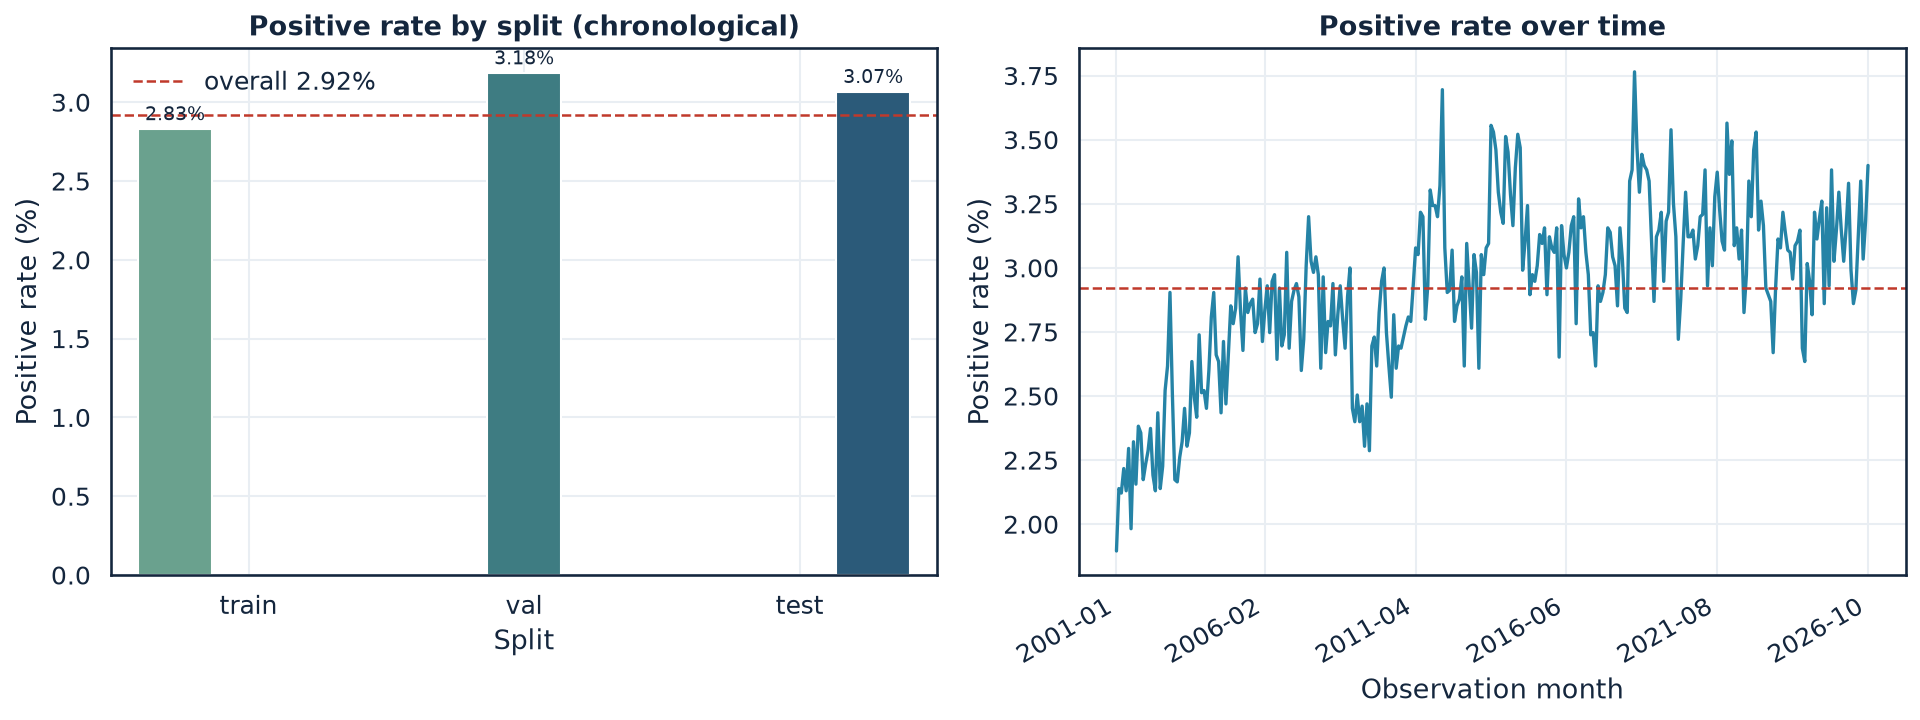

In [5]:
pos = int(features["target"].sum())
total = len(features)
print(f"Positives : {pos:,} / {total:,}  = {100 * pos / total:.2f}%")
print(f"Imbalance : 1 : {(total - pos) / pos:.1f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- by split ---
split_rate = features.groupby("split")["target"].agg(["count", "sum", "mean"]).reset_index()
split_rate["rate_pct"] = 100 * split_rate["mean"]

sns.barplot(data=split_rate, x="split", y="rate_pct", hue="split",
            palette="crest", legend=False, ax=axes[0],
            order=["train", "val", "test"])
axes[0].axhline(100 * pos / total, color="#C0392B", ls="--", lw=1.2,
                label=f"overall {100 * pos / total:.2f}%")
axes[0].set_ylabel("Positive rate (%)")
axes[0].set_xlabel("Split")
axes[0].set_title("Positive rate by split (chronological)")
axes[0].legend(frameon=False)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.2f%%", padding=2, fontsize=9)

# --- over time ---
# tz_localize(None) first: to_period() would otherwise warn about dropping UTC.
monthly = (features.assign(month=features["obs_date"].dt.tz_localize(None).dt.to_period("M"))
           .groupby("month")["target"].mean())
axes[1].plot(range(len(monthly)), 100 * monthly.to_numpy(), color=ACCENT, lw=1.6)
axes[1].axhline(100 * pos / total, color="#C0392B", ls="--", lw=1.2)
axes[1].set_xlabel("Observation month")
axes[1].set_ylabel("Positive rate (%)")
axes[1].set_title("Positive rate over time")
ticks = np.linspace(0, len(monthly) - 1, 6).astype(int)
axes[1].set_xticks(ticks)
axes[1].set_xticklabels([str(monthly.index[t]) for t in ticks], rotation=30, ha="right")

for ax in axes:
    ax.grid(color=LIGHT)
    ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig("reports/figures/features_class_balance.png", bbox_inches="tight")
plt.show()

Consistent positive rates across train/val/test (and across 26 years) are a
**good sign**: the chronological split has not shifted the problem, so a model
validated on `val` is being tested on the same phenomenon it was trained on.

## 4. Class balance by region

A single global positive rate hides regional differences. Regions differ in
how often a cell sees a large event, which affects both difficulty and the
trustworthiness of any single global metric — so per-region rates are
reported alongside the global one.

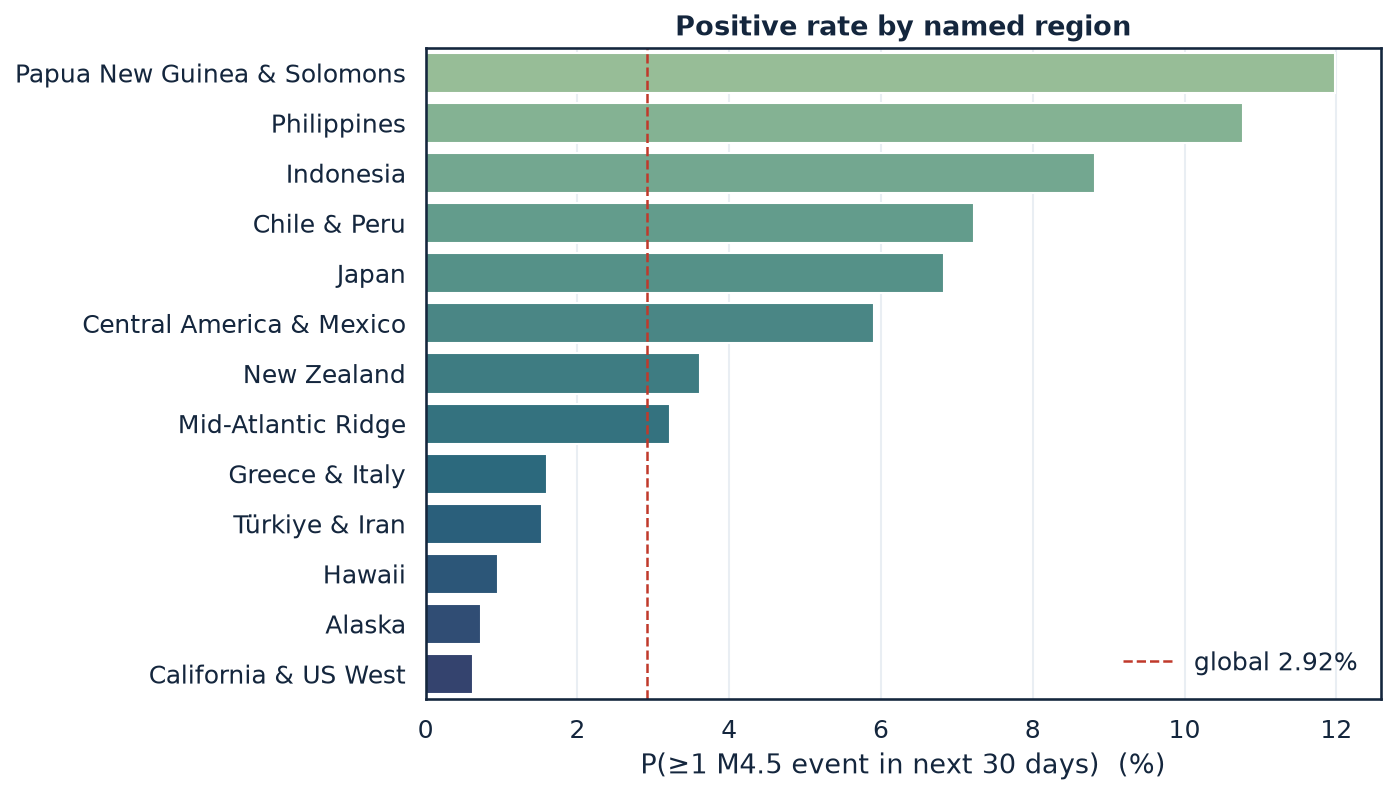

,region,rows,cells,positives,positive_rate_pct
0,Papua New Guinea & Solomons,49290,159,5907,11.984175
1,Philippines,40300,130,4340,10.769231
2,Indonesia,178560,576,15739,8.814404
3,Chile & Peru,86490,279,6244,7.219332
4,Japan,73780,238,5039,6.829764
5,Central America & Mexico,57040,184,3369,5.906381
6,New Zealand,29760,96,1077,3.618952
7,Mid-Atlantic Ridge,137020,442,4409,3.217778
8,Greece & Italy,81220,262,1297,1.596897
9,Türkiye & Iran,100130,323,1538,1.536003


In [6]:
region_rows = []
for name, box in NAMED_REGIONS.items():
    lat_lo, lat_hi = box["lat"]
    lon_lo, lon_hi = box["lon"]
    in_region = (
        features["latitude_center"].between(lat_lo, lat_hi)
        & features["longitude_center"].between(lon_lo, lon_hi)
    )
    subset = features[in_region]
    if subset.empty:
        continue
    region_rows.append({
        "region": name,
        "rows": len(subset),
        "cells": subset["cell_id"].nunique(),
        "positives": int(subset["target"].sum()),
        "positive_rate_pct": 100 * subset["target"].mean(),
    })

region_balance = (pd.DataFrame(region_rows)
                  .sort_values("positive_rate_pct", ascending=False)
                  .reset_index(drop=True))

fig, ax = plt.subplots(figsize=(9.5, 5.5))
sns.barplot(data=region_balance, y="region", x="positive_rate_pct",
            hue="region", palette="crest", legend=False, ax=ax)
ax.axvline(100 * pos / total, color="#C0392B", ls="--", lw=1.2,
           label=f"global {100 * pos / total:.2f}%")
ax.set_xlabel("P(≥1 M4.5 event in next 30 days)  (%)")
ax.set_ylabel("")
ax.set_title("Positive rate by named region")
ax.legend(frameon=False)
ax.grid(axis="x", color=LIGHT)
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig("reports/figures/features_region_balance.png", bbox_inches="tight")
plt.show()

region_balance

In [7]:
spread = region_balance["positive_rate_pct"]
global_rate = 100 * pos / total
below_global = region_balance.loc[
    region_balance["positive_rate_pct"] < global_rate, "region"
].tolist()
print(f"Global positive rate : {global_rate:.2f}%")
print(f"Regional range       : {spread.min():.2f}% → {spread.max():.2f}% "
      f"(spread {spread.max() - spread.min():.2f} pp)")
print(f"Regions below global : {', '.join(below_global) or 'none'}")
print()
print("→ The model must be evaluated per region, not only on the pooled metric.")

# ## 5. Feature sparsity
#
# Most (cell, month) pairs are quiet — which is exactly what makes this a
# probabilistic problem rather than a counting one.

Global positive rate : 2.92%
Regional range       : 0.62% → 11.98% (spread 11.36 pp)
Regions below global : Greece & Italy, Türkiye & Iran, Hawaii, Alaska, California & US West

→ The model must be evaluated per region, not only on the pooled metric.


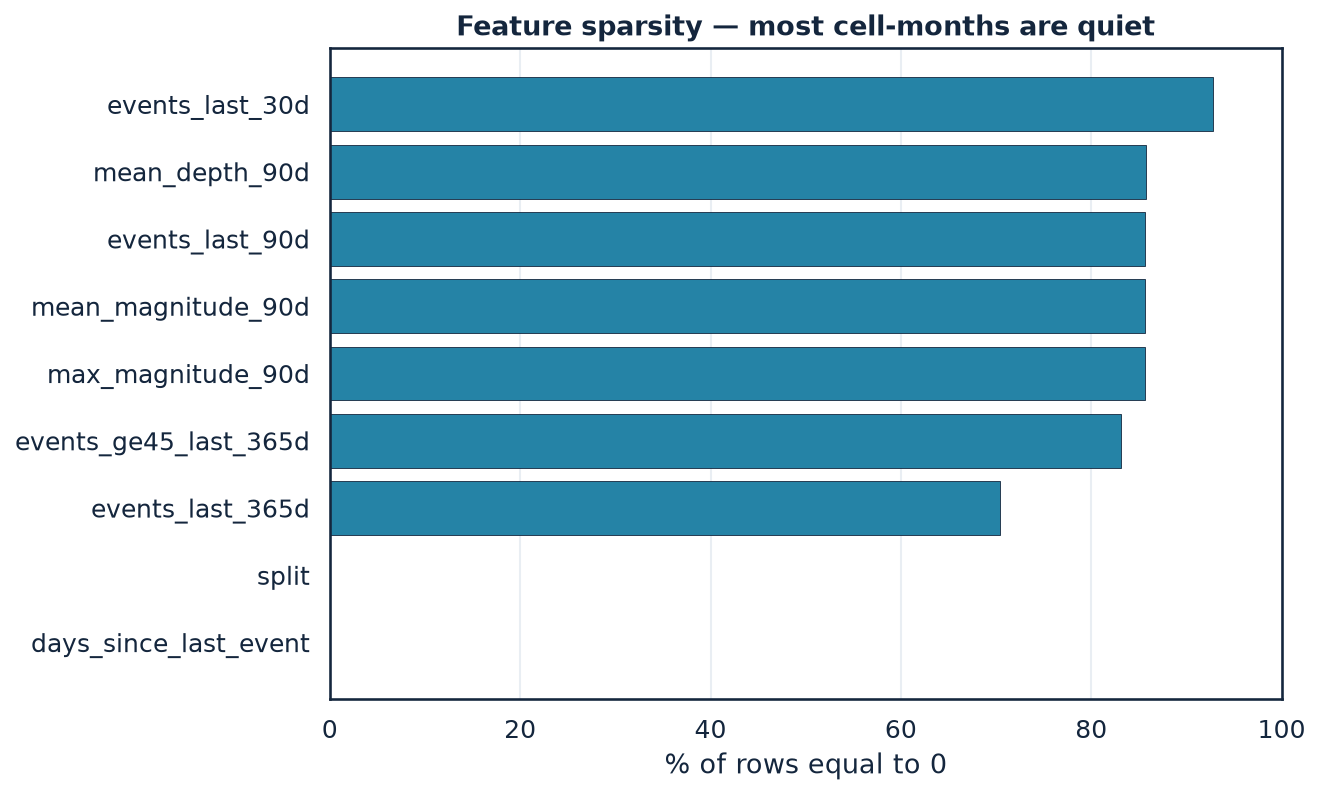

,column,pct_zero,n_unique
7,days_since_last_event,0.000000,2712842
8,split,0.000000,3
2,events_last_365d,70.451215,918
6,events_ge45_last_365d,83.146052,319
4,max_magnitude_90d,85.664217,387
3,mean_magnitude_90d,85.664217,17856
1,events_last_90d,85.664217,443
5,mean_depth_90d,85.729137,124953
0,events_last_30d,92.830790,270


In [8]:
feature_cols = feature_columns(features)

sparse = pd.DataFrame({
    "column": feature_cols,
    "pct_zero": [100 * (features[c] == 0).mean() for c in feature_cols],
    "n_unique": [features[c].nunique() for c in feature_cols],
}).sort_values("pct_zero", ascending=True)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(sparse["column"], sparse["pct_zero"], color=ACCENT,
        edgecolor=NAVY, linewidth=0.4)
ax.set_xlabel("% of rows equal to 0")
ax.set_title("Feature sparsity — most cell-months are quiet")
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color=LIGHT)
fig.tight_layout()
fig.savefig("reports/figures/features_sparsity.png", bbox_inches="tight")
plt.show()

sparse

High sparsity in the trailing-window counts is expected and *informative*:
"no events in the last 30 days" is a genuine signal for a low probability of
a large event next month. The 0-fill convention (documented in
`docs/DATA_DICTIONARY.md`) keeps these rows usable by linear models too.

## 6. Do past events predict future ones?

The core modelling question: does recent activity raise the probability of a
large event in the next 30 days?

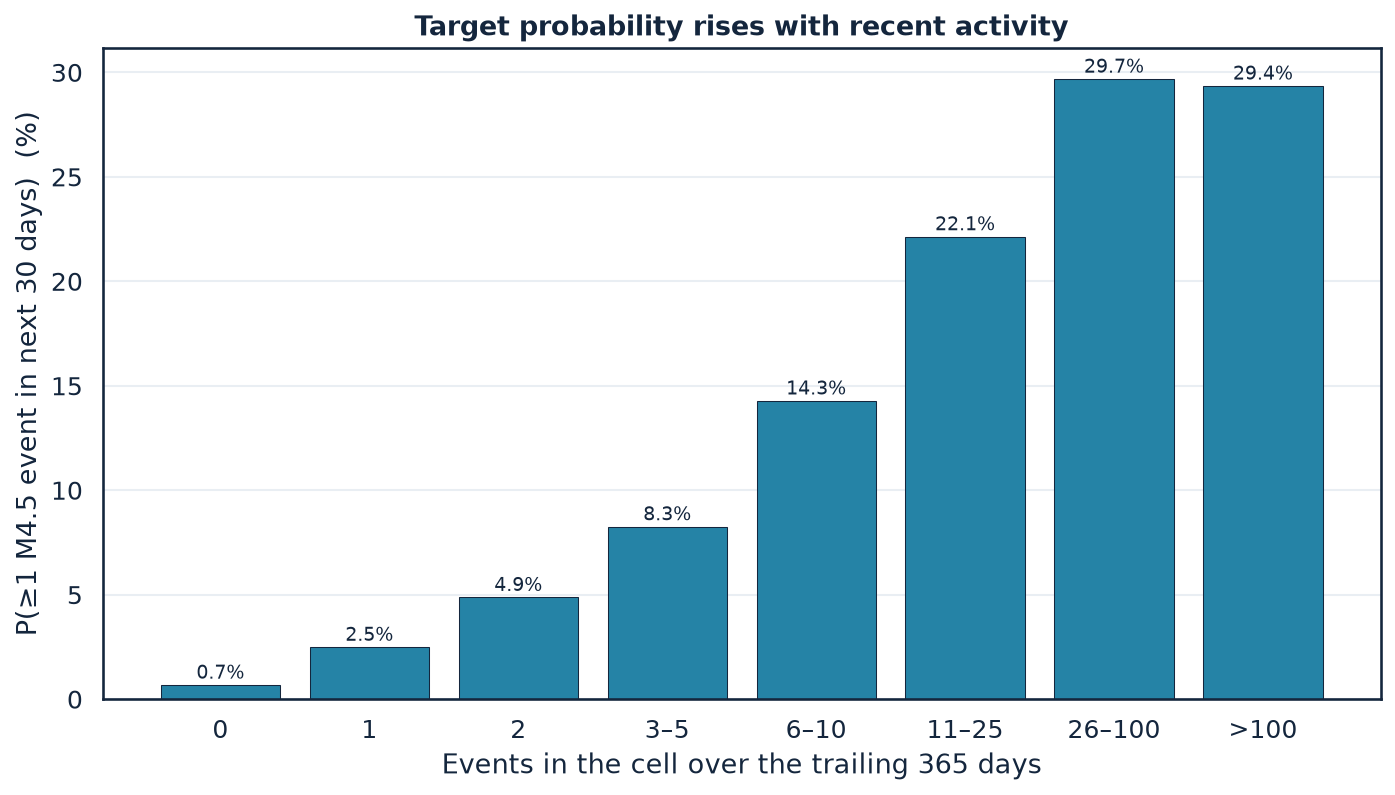

,bucket,count,mean,rate_pct
0,0,2512241,0.006777,0.677682
1,1,430893,0.024895,2.489481
2,2,167699,0.048742,4.874209
3,3–5,201544,0.082592,8.259239
4,6–10,111459,0.142797,14.279690
5,11–25,86098,0.221399,22.139887
6,26–100,46800,0.296838,29.683761
7,>100,9185,0.293522,29.352205


In [9]:
bins = [-1, 0, 1, 2, 5, 10, 25, 100, 10_000]
labels = ["0", "1", "2", "3–5", "6–10", "11–25", "26–100", ">100"]
feat = features.copy()
feat["bucket"] = pd.cut(feat["events_last_365d"], bins=bins, labels=labels)

by_bucket = feat.groupby("bucket", observed=True)["target"].agg(["count", "mean"]).reset_index()
by_bucket["rate_pct"] = 100 * by_bucket["mean"]

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.bar(by_bucket["bucket"], by_bucket["rate_pct"], color=ACCENT,
       edgecolor=NAVY, linewidth=0.5)
ax.set_xlabel("Events in the cell over the trailing 365 days")
ax.set_ylabel("P(≥1 M4.5 event in next 30 days)  (%)")
ax.set_title("Target probability rises with recent activity")
ax.grid(axis="x", visible=False)
ax.grid(axis="y", color=LIGHT)
for i, r in by_bucket.iterrows():
    ax.text(i, r["rate_pct"] + 0.3, f"{r['rate_pct']:.1f}%",
            ha="center", fontsize=9, color=NAVY)
fig.tight_layout()
fig.savefig("reports/figures/features_target_vs_activity.png", bbox_inches="tight")
plt.show()

by_bucket

A clear monotonic relationship — but note it is **probabilistic, not
deterministic**: even the most active cells produce a large event in only a
minority of months. That is the honest shape of earthquake forecasting, and
why calibration (does a predicted 20% verify ~20%?) matters as much as
discrimination.

In [10]:
# How much signal is there overall? A simple rank correlation as a sanity check.
# (pandas' spearman avoids a scipy dependency.)
rho = feat["events_last_365d"].corr(feat["target"], method="spearman")
print(f"Spearman ρ(events_last_365d, target) = {rho:.4f}")

Spearman ρ(events_last_365d, target) = 0.2448


## 7. Catalog completeness — the standing caveat

Absence of recorded events is **not** evidence of absence of seismicity.
Detection and reporting coverage varies by region and by era: a cell can look
"quiet" because nothing happened, or because nobody was listening.

Consequences carried into Module 02:

* Negative labels are only as good as the catalog's detection ability.
* Regional performance must be reported separately — a global average can
  hide a region where the model is systematically wrong.
* We report probabilities with explicit uncertainty rather than point claims.

In [11]:
# Completeness evidence: how the network grew over time.
events_per_year = catalog.groupby(catalog["time"].dt.year).size()
print("Events recorded per year (growth reflects improving coverage, not only seismicity):")
print(events_per_year.to_string())

Events recorded per year (growth reflects improving coverage, not only seismicity):
time
2000    17847
2001    19835
2002    23086
2003    24302
2004    27531
2005    31113
2006    32125
2007    30749
2008    32806
2009    15458
2010    24934
2011    23088
2012    19739
2013    20398
2014    28407
2015    26778
2016    25040
2017    22618
2018    41186
2019    26486
2020    32037
2021    28607
2022    26670
2023    27039
2024    24954
2025    29063
2026    25542


In [12]:
summary = {
    "rows": int(len(features)),
    "positives": pos,
    "positive_rate_pct": round(100 * pos / total, 3),
    "imbalance_ratio": round((total - pos) / pos, 1),
    "spotcheck_rows": int(checked),
    "spotcheck_mismatches": int(count_mismatch + target_mismatch),
    "spearman_rho": round(float(rho), 4),
}
summary

{'rows': 3565930,
 'positives': 104140,
 'positive_rate_pct': 2.92,
 'imbalance_ratio': 33.2,
 'spotcheck_rows': 250,
 'spotcheck_mismatches': 0,
 'spearman_rho': 0.2448}